In [2]:
! python -m pip install gurobipy
! python -m pip install networkx
! python -m pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 25.3 MB/s  0:00:00


In [1]:
import networkx as nx

#  Definizione grafo orientato con NetworkX
G = nx.DiGraph()

## Aggiungi nodi
nodes = [
    ("A", {"bil": -1}),
    ("B", {"bil":  0}),
    ("C", {"bil":  0}),
    ("D", {"bil":  0}),
    ("E", {"bil":  0}),
    ("F", {"bil": +1})
]
G.add_nodes_from(nodes)

## Aggiungi archi (coda, testa, costo)
edges = [
    ("A","B", {"costo":  7, "capacita": 20}) ,
    ("A","C", {"costo":  8, "capacita": 50}) ,
    ("B","C", {"costo": -1, "capacita": 40}) ,
    ("B","D", {"costo":  4, "capacita": 30}) ,
    ("B","E", {"costo":  1, "capacita": 20}) ,
    ("B","F", {"costo":  5, "capacita": 14}) ,
    ("C","F", {"costo":  3, "capacita": 48}) ,
    ("D","F", {"costo":  1, "capacita": 33}) ,
    ("E","C", {"costo": -2, "capacita": 21}) ,
    ("E","D", {"costo":  0, "capacita": 14}) ,
    ("F","E", {"costo":  3, "capacita": 18})
]
G.add_edges_from(edges)

for v in G.nodes: # v è l'identificatore del nodo
  print(f"nodo {v} chiede {G.nodes[v]["bil"]}")
for (i,j) in G.edges: # (i,j) è l'identificatore dell'arco
  print(f"arco {i}->{j} costa {G.edges[i,j]["costo"]} e porta fino a {G.edges[i,j]["capacita"]}")

nodo A chiede -1
nodo B chiede 0
nodo C chiede 0
nodo D chiede 0
nodo E chiede 0
nodo F chiede 1
arco A->B costa 7 e porta fino a 20
arco A->C costa 8 e porta fino a 50
arco B->C costa -1 e porta fino a 40
arco B->D costa 4 e porta fino a 30
arco B->E costa 1 e porta fino a 20
arco B->F costa 5 e porta fino a 14
arco C->F costa 3 e porta fino a 48
arco D->F costa 1 e porta fino a 33
arco E->C costa -2 e porta fino a 21
arco E->D costa 0 e porta fino a 14
arco F->E costa 3 e porta fino a 18


In [3]:
import gurobipy as gp
from gurobipy import GRB

#  Modello Gurobi
m = gp.Model("mcf")

# Variabili (archi)
relax_integrality = False
x = m.addVars(G.edges, vtype = GRB.INTEGER if not relax_integrality else GRB.CONTINUOUS, lb=0.0, name="x")
y = m.addVar(vtype = GRB.INTEGER if not relax_integrality else GRB.CONTINUOUS, lb=0.0, name="maxFlow")

# Vincoli di bilanciamento
for v in G.nodes:
  inflow  = gp.quicksum(x[i, v] for i in G.predecessors(v))
  outflow = gp.quicksum(x[v, j] for j in G.successors(v))
  m.addConstr(inflow - outflow == G.nodes[v]["bil"] * y, name=f"balance[{v}]")

# Vincoli di capacità
for a in G.edges:
  m.addConstr(x[a] <= G.edges[a]["capacita"], name=f"capacity[{a}]")

# Funzione obiettivo
m.setObjective(y, GRB.MAXIMIZE)

m.write("netflow.maxf.lp")

# Ottimizza
m.optimize()



Restricted license - for non-production use only - expires 2028-11-29
Gurobi Optimizer version 14.0.0 build v14.0.0rc1 (linux64 - "Ubuntu 24.04.5 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 17 rows, 12 columns and 35 nonzeros (Max)
Model fingerprint: 0xa2ee8faa
Model has 1 linear objective coefficients
Variable types: 0 continuous, 12 integer (0 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [1e+00, 1e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+01, 5e+01]

Found heuristic solution: objective -0.0000000
Presolve removed 13 rows and 4 columns
Presolve time: 0.00s
Presolved: 4 rows, 8 columns, 16 nonzeros
Found heuristic solution: objective 48.0000000
Variable types: 0 continuous, 8 integer (0 binary)

Root relaxation: objective 6.800000e+01, 2 iterations, 0.00 seconds (0.00 work units)

    Nodes  

In [4]:
#  Risultati
print("\n\nRisultati ottimizzazione:")
archi_con_flusso = []
if m.status == GRB.OPTIMAL:
  m.setParam("OutputFlag",1)
  m.printAttr("x")
  print(f"Funzione obiettivo = {m.objVal:.6g}")
  print("\nArchi selezionati (x[i,j] > 0):")
  for (i, j) in G.edges:
    if x[i, j].X > 1e-6:
      archi_con_flusso.append((i, j))
      print(f"  {i} -> {j} porta {x[i, j].X}")



Risultati ottimizzazione:
Set parameter OutputFlag to value 1

    Variable            x 
-------------------------
      x[A,B]           20 
      x[A,C]           48 
      x[B,D]            6 
      x[B,F]           14 
      x[C,F]           48 
      x[D,F]            6 
     maxFlow           68 
Funzione obiettivo = 68

Archi selezionati (x[i,j] > 0):
  A -> B porta 20.0
  A -> C porta 48.0
  B -> D porta 6.0
  B -> F porta 14.0
  C -> F porta 48.0
  D -> F porta 6.0


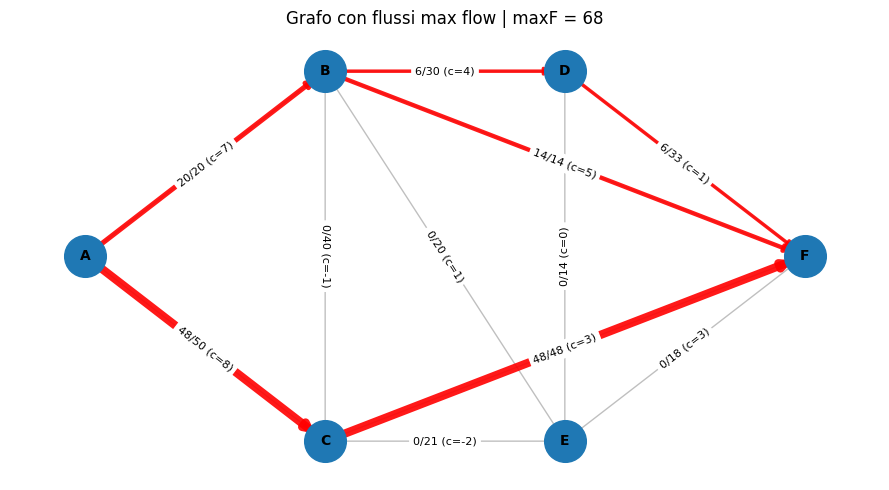

In [6]:
# Visualizzazione
import matplotlib.pyplot as plt

pos = {
    "A": (0, 2),
    "B": (1.5, 3),
    "C": (1.5, 1),
    "D": (3, 3),
    "E": (3, 1),
    "F": (4.5, 2),
}

plt.figure(figsize=(9, 5))

nx.draw_networkx_edges(G, pos, edgelist=list(G.edges), width=1.0, alpha=0.25, arrows=True)

if archi_con_flusso:
    flows = [x[i, j].X for (i, j) in archi_con_flusso]
    fmax = max(flows) if flows else 1.0
    widths = [2.0 + 4.0 * (x[i, j].X / fmax) for (i, j) in archi_con_flusso]
    nx.draw_networkx_edges(G, pos, edgelist=archi_con_flusso, width=widths, alpha=0.9, arrows=True, edge_color="r")

nx.draw_networkx_nodes(G, pos, node_size=900)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight="bold")

edge_labels = {}
for (i, j) in G.edges:
    flow = x[i, j].X if m.status == GRB.OPTIMAL else 0.0
    cap  = G[i][j]["capacita"]
    cost = G[i][j]["costo"]
    if flow > 1e-9:
        edge_labels[(i, j)] = f"{flow:.0f}/{cap} (c={cost})"
    else:
        edge_labels[(i, j)] = f"0/{cap} (c={cost})"
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)

title = "Grafo con flussi max flow"
if m.status == GRB.OPTIMAL:
    title += f" | maxF = {m.objVal:.3g}"
plt.title(title)
plt.axis("off")
plt.tight_layout()
plt.show()